# Robustez, resiliencia al cambio y sobreajuste: curvas de ruido, peores submuestras y puntos débiles


**Pregunta:** ¿Se sostiene el AUC del modelo cuando sus entradas tienen ruido, cuando la población de evaluación se aleja de la de desarrollo y cuando se lo juzga en una muestra reservada y no en los datos con que se ajustó?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema y el notebook 03 del tema 01 (políticas y luces)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- medir cuánto se mueven el AUC y el puntaje de Brier de un modelo cuando se agrega ruido de escala $\varepsilon$ a las entradas, comparar la curva con su valor exacto en una planta y leer el hallazgo contra la tolerancia;
- encontrar las filas de evaluación que menos se parecen a la muestra de desarrollo, puntuar el modelo en esa peor submuestra y decir por qué la caída bruta del AUC no es una prueba por sí sola;
- leer el valor p de la resiliencia al cambio contra una referencia exacta por permutación, y explicar qué elimina la referencia;
- calcular la brecha entre entrenamiento y reserva y los puntos débiles (tramos cuyo error es un múltiplo del promedio), y leer las filas versionadas de Taiwán, Polonia y la Reserva Federal del caso C20 con la versión del motor que las horneó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import generalisation as gen
from riskvalidation.ml import plants
from riskvalidation.ml import robustness as rob
from riskvalidation.validation import ml as vml

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}
YN = {True: "sí", False: "no"}

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

- **Las plantas del motor** (`riskvalidation.ml.plants`), sintéticas y generadas desde una semilla, con la verdad conocida exacta: `NoiseSensitivityPlant` (una columna de señal cuya separación elegimos, de modo que el AUC a cada escala de ruido tiene forma cerrada) y `CovariateShiftPlant` (una muestra de desarrollo, una de evaluación en que una cuarta parte de las filas están desplazadas, y una relación verdadera que cambia más allá del soporte de desarrollo). Cada planta trae una función `predict`, así que el modelo entra al motor solo como un invocable sobre arreglos y el motor no importa ninguna biblioteca de aprendizaje.
- **Tres documentos versionados del caso C20**, leídos por sus filas reales (propietario: este repositorio, derivados de los datos de tarjetas de Taiwán de UCI, CC BY 4.0, clase mirror-allowed, y de los datos de quiebras polacas de UCI y tres carteras corporativas de la Reserva Federal, dominio público): `perturbation-grid.json` (un modelo LightGBM sobre las tarjetas de Taiwán bajo ruido en las entradas), `fed-shift.json` (un modelo sobre las empresas polacas desplazadas hacia la cartera de mayor riesgo de la Reserva Federal) y `seed-sweep.json` (los modelos de Taiwán reajustados con 20 semillas). La cadena de cálculo ajustó los modelos; este notebook lee las filas que escribió e imprime la versión del motor que las horneó.

In [2]:
# Abrir los tres documentos versionados e imprimir la versión del motor que horneó cada uno
variants = {}
for name in ("perturbation-grid", "fed-shift", "seed-sweep"):
    path = ROOT / "data" / "derived" / "C20" / f"{name}.json"
    variants[name] = json.loads(path.read_text(encoding="utf-8"))
    doc = variants[name]
    print(
        f"{name:18s} horneado con riskvalidation",
        doc["provenance"]["riskvalidation_version"],
        "|",
        len(doc["tests"]),
        "filas de prueba",
    )
perturbation, fed, seeds = variants["perturbation-grid"], variants["fed-shift"], variants["seed-sweep"]

perturbation-grid  horneado con riskvalidation 1.0.1 | 16 filas de prueba
fed-shift          horneado con riskvalidation 1.0.1 | 156 filas de prueba
seed-sweep         horneado con riskvalidation 1.0.1 | 22 filas de prueba


## Método

Las tres pruebas siguientes vienen de las pruebas de resultados de PiML (Robustness, Resilience, Overfit y WeakSpot; ver las referencias) tal como las registra el dossier de investigación de riesgo de modelo, y de la guía del BCE sobre sobreajuste y aleatoriedad del entrenamiento. Sus tolerancias son **convenciones con parámetros con nombre**, no umbrales regulatorios.

### Paso 1: robustez, desempeño frente a ruido en las entradas

El ruido se agrega solo a las variables de **evaluación**, nunca al tramo de entrenamiento. Con $s_j$ la desviación estándar muestral (ddof 1) de la columna $j$, $z_{ij}$ normales estándar y $\varepsilon$ la escala en múltiplos de $s_j$:

$$\tilde{x}_{ij} = x_{ij} + \varepsilon\, s_j\, z_{ij}, \qquad \Delta\mathrm{AUC}(\varepsilon) = \mathrm{AUC}(\tilde{X}_\varepsilon) - \mathrm{AUC}(X).$$

Los mismos $z_{ij}$ se usan en todo $\varepsilon$, de modo que las muestras perturbadas quedan anidadas y la curva es suave. El hallazgo se levanta cuando la pérdida a una escala fijada de antemano $\varepsilon^*$ supera la tolerancia $\tau = 0{,}02$ puntos de AUC (una pérdida igual a $\tau$ no es un hallazgo; la pérdida se redondea primero a 12 decimales, porque $0{,}80 - 0{,}78$ es $0{,}020000000000000018$ en coma flotante). La luz es ámbar sobre $\tau$ y roja sobre $2\tau$.

En la planta de ruido la columna de señal es $x_0 = s\,y + N(0,1)$ con prevalencia $\pi = 0{,}3$, así que el AUC a escala $\varepsilon$ se conoce exacto (el `NoiseSensitivityPlant.truth()` del motor):

$$\mathrm{AUC}(\varepsilon) = \Phi\!\left(\frac{s}{\sqrt{2\,\bigl(1 + \varepsilon^2 (1 + s^2 \pi (1-\pi))\bigr)}}\right).$$

La celda siguiente saca 20.000 filas con $s = 1{,}5$, calcula la curva del motor e imprime la curva exacta a su lado.

In [3]:
# La curva de robustez del motor sobre la planta de ruido contra su valor exacto
noise_plant = plants.NoiseSensitivityPlant(n=20000, sensitivity=1.5, seed=11)
draw = noise_plant.sample()
GRID = (0.05, 0.1, 0.25, 0.5, 1.0)
curve = rob.robustness_curve(noise_plant.predict, draw["X"], draw["y"], GRID, seed=5)
truth = noise_plant.truth(curve.grid)
print(f"{'eps':>5s} {'AUC':>8s} {'AUC exacto':>14s} {'delta':>9s} {'Brier':>7s}")
for eps, auc, exact, delta, brier in zip(curve.grid, curve.auc, truth["auc"], curve.auc_delta, curve.brier):
    print(f"{eps:5.2f} {auc:8.4f} {exact:14.4f} {delta:9.4f} {brier:7.4f}")

  eps      AUC     AUC exacto     delta   Brier
 0.00   0.8561         0.8556    0.0000  0.1591
 0.05   0.8561         0.8551   -0.0000  0.1592
 0.10   0.8551         0.8538   -0.0010  0.1595
 0.25   0.8473         0.8449   -0.0088  0.1626
 0.50   0.8214         0.8177   -0.0347  0.1733
 1.00   0.7544         0.7500   -0.1018  0.2078


Las dos curvas coinciden dentro del error de muestreo de 20.000 filas (la mayor diferencia impresa es menor que 0,005). El ruido del motor es función de la semilla únicamente, lo que comprueba la celda siguiente: la misma semilla da los mismos valores en cada escala, y la escala 0 devuelve la entrada sin cambios. Después lee el hallazgo y la luz a dos escalas fijadas de antemano.

In [4]:
# El ruido es anidado (mismas extracciones, escaladas) y eps = 0 es la identidad; luego el hallazgo en dos escalas
small = rob.perturb_features(draw["X"], 0.25, seed=5) - draw["X"]
large = rob.perturb_features(draw["X"], 0.5, seed=5) - draw["X"]
unchanged = rob.perturb_features(draw["X"], 0.0, seed=5)
print("el ruido a la escala mayor es el doble del ruido a la menor:", YN[bool(np.allclose(large, 2 * small))])
print("eps = 0 devuelve la entrada:", YN[bool(np.array_equal(unchanged, draw["X"]))])
for preset in (0.25, 1.0):
    flagged = rob.robustness_finding(curve, tolerance=0.02, preset_eps=preset)
    result = vml.robustness("noise-plant", curve, 0.02, preset)
    print(
        f"eps* = {preset:4.2f} | pérdida de AUC {result.metric:.4f} | hallazgo {YN[bool(flagged)]}", end=" "
    )
    print(f"| luz {LIGHT[result.light.value]}")

el ruido a la escala mayor es el doble del ruido a la menor: sí
eps = 0 devuelve la entrada: sí
eps* = 0.25 | pérdida de AUC 0.0088 | hallazgo no | luz verde
eps* = 1.00 | pérdida de AUC 0.1018 | hallazgo sí | luz rojo


### Paso 2: la misma prueba sobre el modelo de Taiwán versionado

La cadena de cálculo escribió la curva del motor para el modelo LightGBM sobre las tarjetas de Taiwán. Reconstruimos el `RobustnessCurve` del motor desde los valores versionados y llamamos a la prueba y al hallazgo del propio motor sobre él: los números deben ser iguales a los versionados. El documento tiene dos curvas: el ruido de la grilla en todas las variables, y una curva de control que mantiene en cero todo cero exacto (varias columnas de Taiwán son códigos de estado de pago, donde sumar un valor gaussiano a un código no equivale a un error de medición pequeño).

In [5]:
# Reconstruir la curva del motor desde cada fila versionada y llamar a la prueba del motor sobre ella
print("horneado con riskvalidation", perturbation["provenance"]["riskvalidation_version"])
committed_curves = {}
for row in [t for t in perturbation["tests"] if t["test_id"] == "ml.robustness"]:
    ex = row["extras"]
    grid, auc, brier = ex["grid"], ex["auc"], ex["brier"]
    rebuilt = rob.RobustnessCurve(grid=grid, auc=auc, brier=brier, auc_delta=[a - auc[0] for a in auc])
    tol = ex["thresholds"]["perturbation_tolerance"]
    again = vml.robustness(row["model_id"], rebuilt, tol, ex["preset_eps"])
    committed_curves[row["segment"]] = rebuilt
    same = abs(row["metric"] - again.metric) < 1e-9 and row["light"] == again.light.value
    print(
        f"{row['segment']:34s} pérdida versionada {row['metric']:.4f} {LIGHT[row['light']]:6s}"
        f" | motor ahora {again.metric:.4f} {LIGHT[again.light.value]:6s} | igual {YN[same]}"
    )

horneado con riskvalidation 1.0.1
preset-eps-0.1                     pérdida versionada 0.0712 rojo   | motor ahora 0.0712 rojo   | igual sí
control-zeros-kept:preset-eps-0.1  pérdida versionada 0.0081 verde  | motor ahora 0.0081 verde  | igual sí


La curva del modelo versionado enseña algo solo cuando se la pone junto a una curva cuya respuesta el validador
conoce. La celda siguiente dibuja la planta de ruido (la curva del motor sobre la exacta) y las dos curvas
versionadas de Taiwán en los mismos ejes.

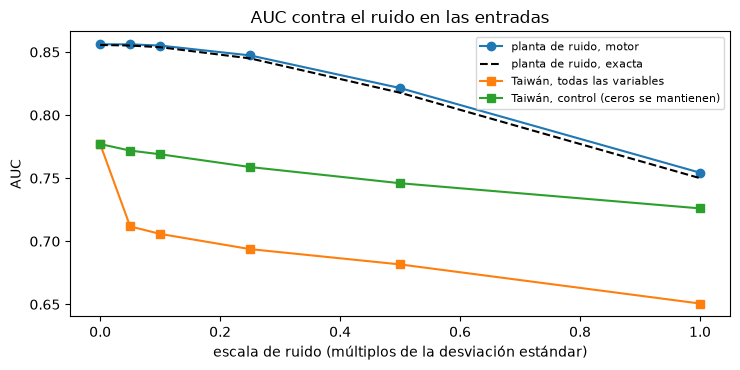

In [6]:
# AUC contra la escala de ruido: la planta de ruido (motor y exacta) y el modelo de Taiwán versionado
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(curve.grid, curve.auc, "o-", label="planta de ruido, motor")
ax.plot(truth["grid"], truth["auc"], "k--", label="planta de ruido, exacta")
for segment, committed in committed_curves.items():
    name = (
        "Taiwán, control (ceros se mantienen)"
        if segment.startswith("control")
        else "Taiwán, todas las variables"
    )
    ax.plot(committed.grid, committed.auc, "s-", label=name)
ax.set_xlabel("escala de ruido (múltiplos de la desviación estándar)")
ax.set_ylabel("AUC")
ax.set_title("AUC contra el ruido en las entradas")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva del motor sobre la planta de ruido queda encima de la exacta, así que la maquinaria de ruido no agrega nada
propio a la pérdida. El modelo de Taiwán con ruido gaussiano en todas las variables cae mucho más rápido que la planta,
y la curva de control, que mantiene en cero todos los ceros exactos, pierde solo 0,0081 con esa escala (0,0712
en la otra). La brecha entre las dos curvas de Taiwán son los códigos de estado de pago y no el modelo: la figura muestra que una luz
de robustez depende de cómo se define el ruido tanto como del modelo al que se aplica.

### Paso 3: resiliencia, la peor submuestra según un puntaje de cambio

La robustez perturba las entradas que ve el modelo. La resiliencia pregunta cómo le va al modelo donde la muestra de evaluación **no se parece al desarrollo**. Dos pasos, ambos en el motor:

1. **El puntaje de cambio.** Un clasificador logístico con crestas distingue filas de desarrollo (clase 0) de filas de evaluación (clase 1); cada fila de evaluación recibe la probabilidad de pertenecer a evaluación, $r_i \in [0,1]$, de un pliegue que no entrenó con ella. Dos muestras que coinciden puntúan 0,5 en promedio.
2. **La peor submuestra.** Las $\lceil q\,n\rceil$ filas de evaluación con mayor $r_i$ (el ejemplo del dossier es $q = 0{,}1$) se puntúan con el mismo modelo: $\Delta = \mathrm{AUC}_{\text{todas}} - \mathrm{AUC}_{\text{peor}}$. Una submuestra con una sola clase no tiene AUC y el motor lanza un error.

En la planta de cambio una cuarta parte de las filas de evaluación tiene la primera covariable desplazada 2 desviaciones estándar, hacia una región donde la relación verdadera invierte su pendiente. El modelo es el ajuste lineal válido dentro del desarrollo. El conjunto de desarrollo debe tener al menos el doble de filas que la evaluación para la referencia del paso siguiente, así que la celda siguiente saca 3.000 filas y conserva las primeras 1.000 de la muestra de evaluación.

In [7]:
# Sacar la planta con desplazamiento y la nula (sin desplazamiento), puntuar la evaluación y tomar el 25% peor
SHARE = 0.25
cases = {}
for label, shift in (("desplazada", 2.0), ("sin desplazamiento", 0.0)):
    plant = plants.CovariateShiftPlant(n=3000, shift=shift, features=[0], seed=3)
    d = plant.sample()
    x_dev, y_dev = d["X_dev"], d["y_dev"]
    x_eval, y_eval, moved = d["X_eval"][:1000], d["y_eval"][:1000], d["shifted"][:1000]
    score = rob.shift_score_rank(x_dev, x_eval, seed=1)
    worst = rob.worst_subsample_performance(plant.predict, x_eval, y_eval, score, SHARE)
    top = np.argsort(-score, kind="stable")[: worst.n]
    cases[label] = (plant, x_dev, y_dev, x_eval, y_eval, score, worst)
    print(f"{label:18s} filas movidas por la planta {moved.mean():.3f}")
    print(f"{'':18s} filas movidas dentro de la submuestra peor {moved[top].mean():.3f}")
    print(
        f"{'':18s} AUC todas las filas {worst.auc_full:.4f} | AUC peor {worst.n} filas {worst.auc:.4f}",
        end=" ",
    )
    print(f"| caída cruda {worst.auc_full - worst.auc:.4f}")

desplazada         filas movidas por la planta 0.242
                   filas movidas dentro de la submuestra peor 0.748
                   AUC todas las filas 0.8842 | AUC peor 250 filas 0.7075 | caída cruda 0.1767
sin desplazamiento filas movidas por la planta 0.000
                   filas movidas dentro de la submuestra peor 0.000
                   AUC todas las filas 0.8965 | AUC peor 250 filas 0.8913 | caída cruda 0.0052


Dos cosas destacan. El puntaje sí encuentra las filas desplazadas: casi toda la peor submuestra son filas que la planta movió. Y **la caída bruta no es cero donde nada se movió**: en la planta sin cambio el peor cuarto según el puntaje es una región del espacio de variables, y el AUC en un rango restringido es menor que en toda la muestra. Una regla como "rojo si la caída supera un número fijo" se activaría entonces sobre un modelo estable. El motor lee la caída contra una referencia construida solo con las filas de desarrollo.

### Paso 4: la referencia por permutación

La referencia responde la pregunta "¿qué tan grande es la caída que muestra un grupo aleatorio de filas de este tamaño y tipo cuando no hay cambio?". Solo con las filas de desarrollo, $R$ veces (el valor por omisión del motor es $R = 199$, una convención):

1. saca un subconjunto aleatorio de las filas de desarrollo del tamaño de la evaluación como conjunto de pseudo-evaluación, siendo las demás filas de desarrollo el conjunto de pseudo-desarrollo;
2. reajusta el puntaje de cambio sobre esa partición, exactamente como en el paso 3;
3. calcula la caída $\Delta^{(b)}$ en las filas de pseudo-evaluación con la misma regla de peor submuestra.

El valor p unilateral por permutación cuenta cuántas veces las caídas nulas alcanzan la observada, incluyendo el valor observado (Phipson y Smyth, 2010: un valor p por permutación nunca es cero):

$$p = \frac{1 + \#\{b : \Delta^{(b)} \ge \Delta_{\text{obs}}\}}{R + 1}.$$

Sin cambio, las filas de evaluación son intercambiables con las de desarrollo, así que la nula es válida y no contiene ninguna fila desplazada, y el efecto de rango restringido del paso 3 está también en la nula. Un sorteo cuya peor submuestra tiene una sola clase no tiene AUC y se deja fuera (`n_undefined`). La luz lee el valor p: roja bajo 0,01, ámbar bajo 0,05. La celda siguiente construye la referencia para ambas plantas y llama a la prueba del motor.

In [8]:
# Construir la referencia solo de desarrollo con 199 permutaciones por planta y llamar a la prueba del motor
resilience = {}
for label, (plant, x_dev, y_dev, x_eval, y_eval, score, worst) in cases.items():
    reference = rob.shift_development_reference(
        plant.predict, x_dev, y_dev, x_eval, y_eval, score, SHARE, shift_permutations=199, seed=2
    )
    result = vml.shift_resilience("shift-plant", worst, reference)
    resilience[label] = (reference, result)
    ex = result.extras
    print(
        f"{label:18s} caída observada {reference.observed_drop:.4f} | media nula {ex['null_mean']:.4f}",
        end=" ",
    )
    print(f"| percentil 95 nulo {ex['null_p95']:.4f}")
    print(f"{'':18s} p = {result.p_value:.4f} | luz {LIGHT[result.light.value]}", end=" ")
    print(f"| extracciones excluidas {reference.n_undefined}")

desplazada         caída observada 0.1767 | media nula 0.0161 | percentil 95 nulo 0.0820
                   p = 0.0100 | luz ámbar | extracciones excluidas 0
sin desplazamiento caída observada 0.0052 | media nula 0.0161 | percentil 95 nulo 0.0820
                   p = 0.5950 | luz verde | extracciones excluidas 0


Un valor p de 199 extracciones es una posición en un histograma. La celda siguiente dibuja, para cada planta, las
caídas nulas construidas solo con las filas de desarrollo y marca la caída observada en el peor cuarto de las filas
de evaluación.

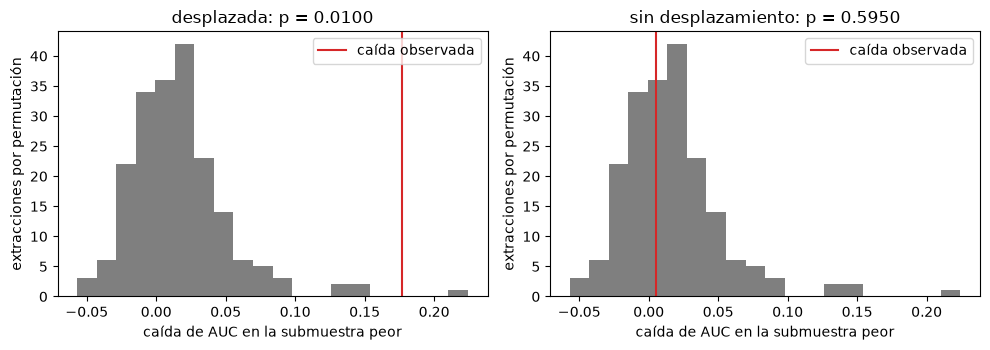

In [9]:
# Caídas nulas de la referencia por permutación contra la caída observada, en ambas plantas
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for ax, (label, (reference, result)) in zip(axes, resilience.items()):
    ax.hist(reference.null_drops, bins=20, color="tab:gray")
    ax.axvline(reference.observed_drop, color="tab:red", label="caída observada")
    ax.set_title(f"{label}: p = {result.p_value:.4f}")
    ax.set_xlabel("caída de AUC en la submuestra peor")
    ax.set_ylabel("extracciones por permutación")
    ax.legend()
fig.tight_layout()
plt.show()

El histograma gris es lo que muestra un grupo aleatorio de filas de este tamaño cuando nada se movió, y no está
centrado en cero: su media es 0,0161 y su percentil 95 es 0,0820, porque cualquier peor cuarto según un puntaje de
desplazamiento es una región restringida. En la planta desplazada la caída observada de 0,1767 queda más allá de casi
todas las extracciones nulas (p = 0,0100), mientras que en la planta sin desplazamiento la caída de 0,0052 cae dentro
del grueso (p = 0,5950). Como el solo nulo llega a 0,0820 en su percentil 95, un corte fijo como 0,05 se activaría en
muchos modelos estables, por eso el motor lee la caída contra esta referencia.

### Paso 5: ventanas fuera de tiempo

La segunda lectura de resiliencia es el AUC de cada ventana fuera de tiempo, y una ventana se deja fuera cuando tiene una sola clase (nunca recibe un número). Las plantas no tienen calendario, así que dos agrupaciones hacen de ventanas: cuatro bloques de filas consecutivas de evaluación (las filas están en orden aleatorio, así que los bloques deben coincidir), y la marca propia de la planta de filas desplazadas contra no desplazadas. La función del motor acepta cualquier etiqueta entera de ventana.

In [10]:
# AUC por ventana para cuatro bloques de filas y para la marca de desplazada de la planta
plant, x_dev, y_dev, x_eval, y_eval, score, worst = cases["desplazada"]
shifted_plant = plants.CovariateShiftPlant(n=3000, shift=2.0, features=[0], seed=3)
moved_flag = shifted_plant.sample()["shifted"][:1000].astype(int)
blocks = np.repeat(np.arange(4), 250)
for label, window in (
    ("cuatro bloques de filas", blocks),
    ("sin desplazar (0) contra desplazada (1)", moved_flag),
):
    by_window = rob.oot_window_performance(plant.predict, x_eval, y_eval, window)
    shown = {("omitida" if k == "omitted" else k): round(v, 4) for k, v in by_window.items()}
    print(label + ":", shown)

cuatro bloques de filas: {'0': 0.903, '1': 0.8832, '2': 0.8663, '3': 0.8862, 'omitida': 0.0}
sin desplazar (0) contra desplazada (1): {'0': 0.8893, '1': 0.7871, 'omitida': 0.0}


### Paso 6: la brecha de sobreajuste

La prueba de sobreajuste compara la métrica en el tramo de entrenamiento con la métrica en la reserva:

$$\text{brecha} = \mathrm{AUC}_{\text{entrenamiento}} - \mathrm{AUC}_{\text{reserva}} \quad (\text{para el puntaje de Brier el signo se invierte}),\qquad \text{marca si brecha} > 0{,}05 .$$

La tolerancia 0,05 es una convención con nombre. La brecha se redondea a 12 decimales antes de compararla, así que una brecha que es exactamente la tolerancia en decimales no se marca: $0{,}80 - 0{,}75$ es $0{,}050000000000000044$ en coma flotante. La luz es roja sobre la tolerancia y verde en otro caso, nunca ámbar. El motor recibe las dos métricas como números, así que la celda siguiente muestra la regla sobre pares escritos en la celda, incluido el límite.

In [11]:
# La regla de sobreajuste en pares escritos en la celda: bajo, en y sobre la tolerancia, y la dirección del Brier
for train, holdout in ((0.78, 0.76), (0.80, 0.75), (0.80, 0.74)):
    r = gen.overfit_gap(train, holdout, tolerance=0.05)
    light = vml.overfit("demo", r).light.value
    print(f"AUC {train:.2f} / {holdout:.2f} | cruda {train - holdout!r} | brecha usada {r.gap!r}", end=" ")
    print(f"| marca {YN[bool(r.flag)]} | luz {LIGHT[light]}")
brier = gen.overfit_gap(0.10, 0.17, tolerance=0.05, higher_is_better=False)
print("Brier 0.10 / 0.17 | brecha", brier.gap, "| marca", YN[bool(brier.flag)])

AUC 0.78 / 0.76 | cruda 0.020000000000000018 | brecha usada 0.02 | marca no | luz verde
AUC 0.80 / 0.75 | cruda 0.050000000000000044 | brecha usada 0.05 | marca no | luz verde
AUC 0.80 / 0.74 | cruda 0.06000000000000005 | brecha usada 0.06 | marca sí | luz rojo
Brier 0.10 / 0.17 | brecha 0.07 | marca sí


### Paso 7: puntos débiles

Un modelo puede ser bueno en promedio y malo en un rincón. La prueba de puntos débiles divide los datos por una variable (aquí los deciles de la primera covariable), toma la pérdida por fila (el término de Brier $(p_i - y_i)^2$) e informa cada tramo con al menos $n_{\min} = 30$ filas cuya pérdida media supera $k = 2$ veces la media general:

$$\text{razón}_s = \frac{\bar{e}_s}{\bar{e}}, \qquad \text{punto débil si } \text{razón}_s > k .$$

La luz es ámbar cuando la peor razón supera $k$ y verde en otro caso; nunca es roja. La planta de ruido tiene una segunda columna de puro ruido, así que un modelo que usa solo la columna de señal es igual de bueno en todo tramo de ella. La celda siguiente corre primero la prueba sobre ese modelo honesto y después **planta un defecto**: en un decil de la columna de ruido la probabilidad del modelo se reemplaza por su complemento (el modelo está al revés ahí). Un validador planta un defecto para ver si la prueba lo encuentra.

In [12]:
# Cortar las filas de la planta de ruido por decil de la columna de ruido: el modelo honesto y un corte al revés
probability = noise_plant.predict(draw["X"])
edges = np.quantile(draw["X"][:, 1], np.linspace(0, 1, 11)[1:-1])
slice_label = np.digitize(draw["X"][:, 1], edges)
PLANTED_SLICE = 6
damaged = np.where(slice_label == PLANTED_SLICE, 1.0 - probability, probability)
models = (("modelo honesto", probability), ("modelo con el corte 6 al revés", damaged))
for label, p in models:
    error = (p - draw["y"]) ** 2
    spots = gen.weak_spots(error, slice_label, k=2.0, min_n=30)
    result = vml.weak_spot("noise-plant", spots, 2.0, len(np.unique(slice_label)))
    print(f"{label:34s} error medio global {error.mean():.4f} | puntos débiles {len(spots)}", end=" ")
    print(f"| luz {LIGHT[result.light.value]} | peor razón {result.metric:.3f}")
    for sp in spots:
        print(f"    corte {sp.label} | n {sp.n} | error medio {sp.mean_error:.4f} | razón {sp.ratio:.3f}")

modelo honesto                     error medio global 0.1591 | puntos débiles 0 | luz verde | peor razón 0.000
modelo con el corte 6 al revés     error medio global 0.1901 | puntos débiles 1 | luz ámbar | peor razón 2.448
    corte 6 | n 2000 | error medio 0.4655 | razón 2.448


La salida anterior lista un solo corte, y la forma del daño se ve mejor en los diez a la vez. La celda siguiente dibuja
el error medio de cada decil para el modelo honesto y para el que tiene el corte 6 al revés, contra el umbral del
doble del error medio global.

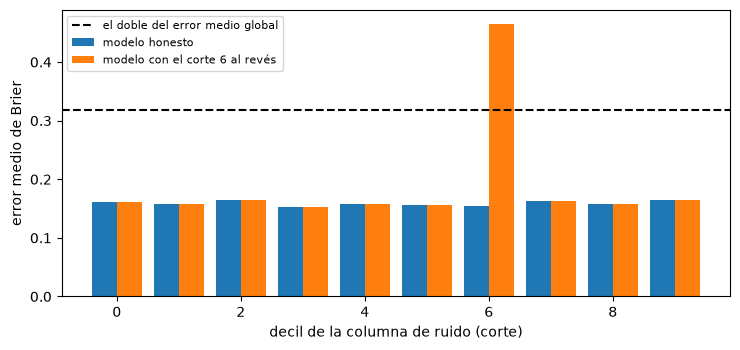

In [13]:
# Error medio por decil de la columna de ruido: el modelo honesto y el modelo con un corte al revés
fig, ax = plt.subplots(figsize=(7.5, 3.6))
slices = np.arange(10)
for offset, (label, p) in zip((-0.2, 0.2), models):
    error = (p - draw["y"]) ** 2
    by_slice = [error[slice_label == s].mean() for s in slices]
    ax.bar(slices + offset, by_slice, width=0.4, label=label)
overall = ((probability - draw["y"]) ** 2).mean()
ax.axhline(2 * overall, color="black", linestyle="--", label="el doble del error medio global")
ax.set_xlabel("decil de la columna de ruido (corte)")
ax.set_ylabel("error medio de Brier")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El modelo honesto tiene el mismo error en todos los deciles, todos muy por debajo de la línea punteada. El modelo
dañado difiere en un solo decil, el corte 6, cuyo error medio de 0,4655 es la única barra sobre el umbral; los otros
nueve no cambian. Una métrica global lo difumina: el error global solo sube de 0,1591 a 0,1901, mientras que la vista
por cortes muestra exactamente dónde se equivoca el modelo y cuánto, que es lo que informa la prueba de puntos débiles.

### Paso 8: las filas versionadas del caso C20

La cadena de cálculo corrió estas pruebas sobre modelos reales y escribió una fila de cada una. La celda siguiente lista las filas de sobreajuste y de puntos débiles de los tres documentos con su brecha, su razón y su luz, y la fila de resiliencia al cambio del desplazamiento de la Reserva Federal con la referencia por permutación que usó. El motor que las horneó es la versión impresa en la sección de Datos.

In [14]:
# Listar las filas versionadas de sobreajuste, puntos débiles y resiliencia al desplazamiento
wanted = ("ml.overfit", "ml.weak_spot", "ml.shift_resilience")
for label, doc in (("perturbation-grid", perturbation), ("fed-shift", fed), ("seed-sweep", seeds)):
    for t in doc["tests"]:
        if t["test_id"] not in wanted:
            continue
        extra = ""
        if t["test_id"] == "ml.weak_spot":
            extra = f" | cortes {t['n']} puntos débiles {t['extras']['n_spots']}"
        if t["test_id"] == "ml.shift_resilience":
            x = t["extras"]
            extra = (
                f" | p {t['p_value']:.4f} media nula {x['null_mean']:.4f} extracciones {x['shift_permutations']}"
                f" AUC todas/peor {x['auc_full']:.4f}/{x['auc_worst']:.4f}"
            )
        head = f"{label:18s} {t['test_id']:20s} {t['model_id'][:22]:22s}"
        print(head, f"valor {t['metric']:.4f} luz {LIGHT[t['light']]}{extra}")

perturbation-grid  ml.overfit           P4-lightgbm-taiwan     valor 0.0297 luz verde
perturbation-grid  ml.weak_spot         P4-lightgbm-taiwan     valor 0.0000 luz verde | cortes 11 puntos débiles 0
fed-shift          ml.shift_resilience  P4-lightgbm-polish     valor 0.0857 luz rojo | p 0.0050 media nula 0.0007 extracciones 199 AUC todas/peor 0.6914/0.6056
fed-shift          ml.overfit           P4-lightgbm-polish     valor 0.0843 luz rojo
seed-sweep         ml.overfit           P4-lightgbm-taiwan     valor 0.0297 luz verde
seed-sweep         ml.overfit           P4-xgboost-taiwan      valor 0.0242 luz verde


## Resultados

**Respuesta:** No incondicionalmente: el modelo aguanta el ruido leve y falla donde las pruebas están hechas para mirar. En la planta de ruido la pérdida de AUC es 0,0088 con una escala de ruido de 0,25 (verde) y 0,1018 con 1,00 (rojo); el modelo de Taiwán versionado pierde 0,0712 con una escala de 0,1 cuando el ruido va en todas las variables, contra 0,0081 cuando se mantienen los ceros exactos. En una muestra de evaluación desplazada el AUC cae de 0,8842 a 0,7075 en el peor cuarto (p de permutación = 0,0100), y el modelo polaco versionado sobreajusta con una brecha de 0,0843 (rojo).

- **La curva de ruido del motor es la curva exacta.** En la planta de ruido el AUC medido sigue la forma cerrada en cada escala (la mayor diferencia impresa es menor que 0,005, el error de muestreo de 20.000 filas), y el hallazgo sigue la tolerancia: a una escala fijada de antemano de 0,25 la pérdida es 0,0088 y la luz es verde, a 1,00 es 0,1018, un hallazgo, y roja.
- **El modelo de Taiwán versionado no pasa la prueba de ruido, y la curva de control dice por qué.** Agregar ruido a todas las variables cuesta 0,0712 de AUC a la escala 0,1 (rojo); la curva de control que mantiene en cero todo cero exacto cuesta 0,0081 (verde). Reconstruidas desde los valores versionados y pasadas por la prueba del motor, ambas filas dan la pérdida y la luz versionadas. La diferencia entre las dos curvas son los códigos de estado de pago: un valor gaussiano sumado a un código no es un error de medición, así que la luz roja mide la elección del ruido tanto como el modelo. Un validador debe leer las dos curvas juntas.
- **El puntaje de cambio encuentra las filas desplazadas, y la caída bruta necesita su referencia.** En la planta con cambio el 74,8% del peor cuarto según el puntaje son filas que la planta movió (el 24,2% de la muestra), y el AUC cae de 0,8842 a 0,7075, una caída de 0,1767. Donde nada se movió la caída es pequeña (0,0052), pero la referencia solo de desarrollo muestra lo que hace el azar: las caídas nulas promedian 0,0161 y su percentil 95 es 0,0820, porque el peor cuarto según un puntaje de cambio es una región del espacio de variables y el AUC en un rango restringido es menor. El valor p por permutación es 0,0100 (ámbar) en la planta con cambio y 0,5950 (verde) en la planta sin cambio. El menor valor p que pueden dar 199 sorteos es 0,005.
- **Las ventanas fuera de tiempo concuerdan con la planta.** Cuatro bloques de filas dan un AUC entre 0,8663 y 0,9030; las filas desplazadas dan 0,7871 contra 0,8893 de las no desplazadas.
- **La regla de sobreajuste es exacta en el límite.** El par 0,80 y 0,75 tiene una brecha en coma flotante de 0,050000000000000044 y una brecha redondeada de 0,05, que no supera la tolerancia: verde. El par 0,80 y 0,74 se marca y es rojo. Para el puntaje de Brier la dirección se invierte, y un aumento de 0,07 es una brecha de 0,07.
- **La prueba de puntos débiles encuentra solo lo que hay.** El modelo honesto no tiene ningún tramo sobre el doble del error medio (verde). Con un decil de la columna de ruido puesto al revés, el error general sube de 0,1591 a 0,1901 y la prueba informa ese tramo con una razón de 2,448 (ámbar), que una métrica global habría difuminado.
- **Las filas versionadas son las mismas pruebas sobre modelos reales.** La brecha del LightGBM de Taiwán es 0,0297 (verde) y sus once tramos de la columna de estado de pago PAY_0 no contienen ningún punto débil; el reajuste con XGBoost da 0,0242 (verde). El modelo LightGBM polaco tiene una brecha de 0,0843 (rojo). En el desplazamiento de la Reserva Federal al ancla completa, el peor décimo tiene un AUC de 0,6056 contra 0,6914 de todas las filas, una caída de 0,0857 con p = 0,0050 sobre 199 sorteos y una media nula de 0,0007: rojo. Todas las filas se hornearon con riskvalidation 1.0.1.

Lo que los resultados no muestran: las plantas no tienen calendario, así que las ventanas son sustitutos; el desplazamiento del documento de la Reserva Federal es sintético y dimensionado por el PSI de una calificación, no un cambio observado en las empresas polacas; las tolerancias (0,02, 0,05, 2), la fracción de la peor submuestra y los 199 sorteos son convenciones; y una luz verde es la ausencia de estos hallazgos particulares.

## Resumen

- La robustez agrega ruido de escala $\varepsilon$ solo a las variables de evaluación, con los mismos valores en cada escala, y levanta un hallazgo cuando la pérdida de AUC a una escala fijada de antemano supera la tolerancia; la curva del motor coincide con la curva exacta de la planta.
- La resiliencia puntúa el modelo en las filas de evaluación que menos se parecen al desarrollo; la caída bruta del AUC es positiva incluso sin cambio, así que el motor la lee contra una referencia exacta por permutación construida con las filas de desarrollo (199 sorteos, p = (1 + conteo) / (R + 1)).
- El sobreajuste es la brecha entre entrenamiento y reserva contra 0,05, exacta en el límite; los puntos débiles son los tramos cuyo error es más del doble del promedio, con al menos 30 filas.
- Las filas versionadas de C20 son las mismas pruebas sobre modelos reales, todas horneadas con riskvalidation 1.0.1: el modelo de Taiwán falla la prueba de ruido solo cuando el ruido se suma a códigos de estado, el modelo polaco sobreajusta y el desplazamiento sintético de la Reserva Federal se encuentra.
- Toda tolerancia es una convención con nombre, y una luz verde es la ausencia de un hallazgo.

**Qué probar después.** El notebook 03 pregunta si las explicaciones del mismo modelo se mantienen cuando cambia la semilla de entrenamiento. El notebook 13-09 mide con qué frecuencia la prueba de resiliencia se activa sobre un modelo que no cambió, y con qué frecuencia encuentra uno que sí cambió.

## Referencias

- PiML-Toolbox (Apache-2.0), pruebas de resultados WeakSpot, Overfit, Reliability, Robustness y Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Phipson, B. y Smyth, G. K. (2010), Permutation p-values should never be zero, Statistical Applications in Genetics and Molecular Biology 9(1). https://doi.org/10.2202/1544-6115.1585
- Yeh, I-C. y Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), las tarjetas de Taiwán de las variantes de C20. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- Board of Governors of the Federal Reserve System, escenarios y datos de metodología de las pruebas de tensión supervisoras (dominio público), las tres carteras corporativas de 2025. https://www.federalreserve.gov/supervisionreg/dfa-stress-tests-2026.htm